# Incompressible LES: Pitz Daily with an Equinox DNN

## Preamble

In [51]:
# Standard Library
from pathlib import Path
from zipfile import ZipFile
import warnings

# Data and Numerical Computing
import gdown
import numpy as np

# FoamNordic
import foamnordic as fno

# Machine Learning
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MaxAbsScaler, StandardScaler

# Visualisation
import matplotlib.pyplot as plt
from IPython.display import display

import equinox as eqx
import jax
import jax.numpy as jnp
import hedgehogs as hdg
import optax

### Directories

In [52]:
# Case Type and Name
CASE_TYPE = "les"
CASE_NAME = "pitzDailySmag"
CATEGORY = "incompressible"

# FoamNordic Project Directory
PROJECT_DIR = Path.cwd().resolve()
BASE_DIR = next((path for path in (PROJECT_DIR, *PROJECT_DIR.parents) if (path / "tutorials" / "openfoam_tutorials").is_dir()), None)
if BASE_DIR is None:
    raise FileNotFoundError("Run this notebook from inside the FoamNordic source tree")

MAIN_DIR = BASE_DIR / "tutorials" / "foamnordic_tutorials" / CATEGORY
OF_SCRIPT_DIR = BASE_DIR / "tutorials" / "openfoam_tutorials" / CATEGORY / CASE_TYPE / CASE_NAME

# Output Directory
MODEL_DIR = MAIN_DIR / "model"
OUTPUT_DIR = MAIN_DIR / "output"
DATA_DIR = OUTPUT_DIR / "data"

for directory in [MODEL_DIR, OUTPUT_DIR, DATA_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

### Configuration

In [53]:
# DataGraph Configuration
FIG_X, FIG_Y = hdg.figsize()
FIGURE_SIZE = (FIG_X, FIG_Y)
PALETTE = hdg.get_palette()
hdg.set_style()

In [54]:
# Reproducibility
SEED = 42
N_TRAIN = 30000
key_jax = jax.random.PRNGKey(SEED)

# ML configuration
LEARNING_RATE = 1.0e-3
BATCH_SIZE = 64
N_EPOCHS = 100

In [55]:
# HPC configuration
ACCOUNT = "<allocation-account>" # e.g. project_xxxxxxx
PARTITION = "small"
TIME = "00:15:00"
N_NODES = 1
N_TASKS = 1
CPUS_PER_TASK = 1
MEM_PER_CPU = "2G"

# FoamNordic Slurm configuration
of_scheduler = fno.Slurm.openfoam(
    nodes=N_NODES,
    ntasks=N_TASKS,
    cpus_per_task=CPUS_PER_TASK,
    mem_per_cpu=MEM_PER_CPU,
)

model_scheduler = fno.Slurm.model(
    cpus_per_task=1,
    mem_per_cpu=MEM_PER_CPU,
)

scheduler = fno.Slurm(
    account=ACCOUNT,
    partition=PARTITION,
    time=TIME,
    openfoam=of_scheduler,
    model=model_scheduler,
)

## Equinox DNN Closure

### Data

In [56]:
# Download the prepared LES data
DATA_ID = "1Kcanmq9og6a8Dy4EDWZSQJyceaQlASTD"
DATA_URL = f"https://drive.google.com/uc?id={DATA_ID}"
DATA_ARCHIVE = OUTPUT_DIR / "pitz_daily_smag_data.zip"
DATA_FILES = (
    "X_train.npy",
    "y_train.npy",
    "X_val.npy",
    "y_val.npy",
    "X_test.npy",
    "y_test.npy",
)

if not all((DATA_DIR / filename).is_file() for filename in DATA_FILES):
    gdown.download(
        url=DATA_URL,
        output=str(DATA_ARCHIVE),
        quiet=False,
    )

    with ZipFile(DATA_ARCHIVE) as archive:
        archive.extractall(DATA_DIR)

# Load the training, validation, and test splits
X_train = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")
X_test = np.load(DATA_DIR / "X_test.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

# Select a deterministic training subset
if len(X_train) > N_TRAIN:
    random_generator = np.random.default_rng(seed=SEED)
    train_indices = random_generator.choice(len(X_train), size=N_TRAIN, replace=False)
    X_train = X_train[train_indices]
    y_train = y_train[train_indices]

In [57]:
# Scale the inputs and target
X_scaler = StandardScaler()
y_scaler = MaxAbsScaler()

X_train = X_scaler.fit_transform(X_train)
X_val = X_scaler.transform(X_val)
X_test = X_scaler.transform(X_test)

y_train = y_scaler.fit_transform(y_train.reshape(-1, 1)).ravel()
y_val = y_scaler.transform(y_val.reshape(-1, 1)).ravel()
y_test = y_scaler.transform(y_test.reshape(-1, 1)).ravel()

y_test_true = y_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

In [58]:
# FoamNordic export configuration
inputs = {
    "velocity_grad": fno.Tensor.tensor(components=9, dtype="float64"),
    "delta": fno.Tensor.scalar(dtype="float64"),
}

outputs = {
    "nut": fno.Tensor.scalar(dtype="float64"),
}

### Model Definition

In [59]:
# Linear layer definition
class Linear(eqx.Module):
    weight: jax.Array
    bias: jax.Array

    def __init__(self, key, in_features, out_features, init="glorot"):
        if isinstance(init, str):
            init_map = {
                "glorot": jax.nn.initializers.glorot_normal(),
                "he": jax.nn.initializers.he_normal(),
                "lecun": jax.nn.initializers.lecun_normal(),
            }
            init = init_map.get(init.lower(), jax.nn.initializers.glorot_normal())

        self.weight = init(key, (out_features, in_features))
        self.bias = jnp.zeros(out_features, dtype=self.weight.dtype)

    def __call__(self, x):
        return self.weight @ x + self.bias

In [60]:
# Multi-layer Perceptron (MLP) definition
class MLP(eqx.Module):
    layers: list
    activation: callable = eqx.field(static=True)

    def __init__(
        self,
        key,
        input_dim,
        hidden_dims,
        output_dim,
        activation=jax.nn.relu,
        init="glorot",
    ):
        self.activation = activation

        dims = [input_dim, *hidden_dims, output_dim]
        keys = jax.random.split(key, len(dims) - 1)

        self.layers = [
            Linear(key=k, 
                   in_features=in_dim, 
                   out_features=out_dim, 
                   init=init)
            for k, in_dim, out_dim in zip(keys, dims[:-1], dims[1:])
        ]

    def __call__(self, x):
        for layer in self.layers[:-1]:
            x = self.activation(layer(x))

        return self.layers[-1](x)

    def predict(self, X):
        return jax.vmap(self.__call__)(X)

In [61]:
# Early stopping
class EarlyStopping:
    """Track validation loss and retain the best model."""

    def __init__(self, patience=20, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = float("inf")
        self.best_epoch = None
        self.best_model = None
        self.should_stop = False

    def update(self, val_loss, model, epoch=None):
        val_loss = float(val_loss)

        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.best_epoch = epoch
            self.best_model = model
            self.counter = 0
        else:
            self.counter += 1

            if self.counter >= self.patience:
                self.should_stop = True

        return self

    def get_best_model(self):
        if self.best_model is None:
            raise RuntimeError("EarlyStopping has not received any model yet.")

        return self.best_model

In [62]:
# Trainer for the MLP model
class MLPTrainer(eqx.Module):
    model: eqx.Module
    optimizer: optax.GradientTransformation = eqx.field(static=True)
    opt_state: optax.OptState

    def __init__(self, model, learning_rate):
        self.model = model
        self.optimizer = optax.adam(learning_rate)
        self.opt_state = self.optimizer.init(
            eqx.filter(self.model, eqx.is_inexact_array)
        )

    def _loss_fn(self, model, X, y):
        y_pred = jax.vmap(model)(X)[:, 0]
        return jnp.mean((y_pred - y) ** 2)

    def loss(self, X, y):
        return self._loss_fn(self.model, X, y)

    def predict(self, X):
        return self.model.predict(X)[:, 0]

    @eqx.filter_jit
    def step(self, X, y):
        loss_value, grads = eqx.filter_value_and_grad(self._loss_fn)(
            self.model, X, y
        )

        updates, opt_state = self.optimizer.update(grads, self.opt_state, self.model)
        model = eqx.apply_updates(self.model, updates)

        trainer = eqx.tree_at(
            lambda t: (t.model, t.opt_state),
            self,
            (model, opt_state),
        )

        return trainer, loss_value

### Model Training

In [63]:
# Convert the data to jax arrays
X_train_jax = jnp.array(X_train)
y_train_jax = jnp.array(y_train)
X_val_jax = jnp.array(X_val)
y_val_jax = jnp.array(y_val)
X_test_jax = jnp.array(X_test)
y_test_jax = jnp.array(y_test)

In [64]:
# Initialise model
input_dim = X_train.shape[1]
output_dim = 1
hidden_dims = [64, 64]
key_model, key_train = jax.random.split(key_jax)

dnn_model = MLP(
    key=key_model,
    input_dim=input_dim,
    hidden_dims=hidden_dims,
    output_dim=output_dim,
    activation=jax.nn.relu,
    init="glorot",
)

trainer = MLPTrainer(
    model=dnn_model,
    learning_rate=LEARNING_RATE,
)

In [65]:
# Hyperparameters
n_samples = X_train_jax.shape[0]
n_batches = n_samples // BATCH_SIZE

# Training monitoring
table = hdg.Table(
    title="DNN Training",
    columns=["Epoch", "Training MSE", "Validation MSE"],
    mode="dynamic",
)

# Early stopping
early_stopping = EarlyStopping(
    patience=30,
    min_delta=1e-8,
)

# Training loop
for epoch in range(N_EPOCHS):
    key_train, subkey = jax.random.split(key_train)
    perm = jax.random.permutation(subkey, n_samples)

    X_shuffled = X_train_jax[perm]
    y_shuffled = y_train_jax[perm]

    training_mse = 0.0

    for i in range(n_batches):
        start_idx = i * BATCH_SIZE
        end_idx = start_idx + BATCH_SIZE

        X_batch = X_shuffled[start_idx:end_idx]
        y_batch = y_shuffled[start_idx:end_idx]

        trainer, batch_loss = trainer.step(X_batch, y_batch)
        training_mse += float(batch_loss)

    training_mse /= n_batches
    validation_mse = float(trainer.loss(X_val_jax, y_val_jax))

    early_stopping.update(
        validation_mse,
        trainer.model,
        epoch=epoch + 1,
    )

    if (epoch + 1) % 20 == 0 or epoch == 0:
        table.add_row([
            epoch + 1,
            f"{training_mse:.6e}",
            f"{validation_mse:.6e}",
        ])

    if early_stopping.should_stop:
        print(
            f"Early stopping at epoch {epoch + 1} | "
            f"Best epoch: {early_stopping.best_epoch} | "
            f"Best validation MSE: {early_stopping.best_loss:.6e}"
        )
        break

# Restore best model
dnn_regressor = early_stopping.get_best_model()

Epoch,Training MSE,Validation MSE
1,1.497393e-02,2.482988e-02
20,8.816194e-04,3.480389e-04
40,4.657053e-05,3.228911e-05
60,3.018644e-05,2.891152e-05
80,1.598771e-05,1.837156e-05
100,1.096747e-05,1.836864e-05


### Model Evaluation

In [66]:
# DNN prediction
y_test_pred_dnn_scaled = np.asarray(dnn_regressor.predict(X_test_jax)).reshape(-1)

y_test_pred_dnn = y_scaler.inverse_transform(y_test_pred_dnn_scaled.reshape(-1, 1)).ravel()

mse_dnn = mean_squared_error(y_test_true, y_test_pred_dnn)
mae_dnn = mean_absolute_error(y_test_true, y_test_pred_dnn)
r2_dnn = r2_score(y_test_true, y_test_pred_dnn)

print(f"MSE: {mse_dnn:.4e}")
print(f"MAE: {mae_dnn:.4e}")
print(f"R2: {r2_dnn:.4f}")

MSE: 5.9889e-12
MAE: 9.0086e-07
R2: 0.9907


In [67]:
negative_mask = y_test_pred_dnn < 0.0

print(f"Negative fraction: {negative_mask.mean():.6e}")
print(f"Minimum prediction: {y_test_pred_dnn.min():.6e}")

Negative fraction: 2.459441e-02
Minimum prediction: -5.972141e-06


### Model Export

In [68]:
# Export the DNN model
MODEL_PATH = MODEL_DIR / "dnn_equinox.fnom"

fno.Export.equinox(
    model=dnn_regressor,
    path=MODEL_PATH,
    inputs=inputs,
    outputs=outputs,
    name="dnn",
    batched=False,
    x_scaler=X_scaler,
    y_scaler=y_scaler,
    verbose=True,
);

Property,Value
Artifact,dnn_equinox.fnom
Payload,embedded .eqx
Format,Equinox + FNOM
Dtype,float64
Input format,numpy
Inputs,"velocity_grad[9], delta[1]"
Outputs,nut[1]
Input scaler,standard
Output scaler,maxabs
Compression,none (load once at worker startup)


### Closure

In [69]:
# Define the learned Smagorinsky closure
closure = fno.Closure(
    name="nutFjord",
    operator=fno.Operator.model(path=MODEL_PATH),
    inputs={
        "velocity_grad": fno.Field.grad(value="U"),
        "delta": fno.Field.delta(),
    },
    outputs={
        "nut": fno.Field(name="nut"),
    },
    key=None,
)

### Case Definition

In [70]:
# Initialise the OpenFOAM case
case = fno.OpenFOAM.Case(
    name="pitzDailySmag-EquinoxDNN",
    case_dir=OF_SCRIPT_DIR,
    run_dir=OUTPUT_DIR,
    of_cmd="module load openfoam/2512",
    shell="bash",
    application="pimpleFoam",
    ranks=N_TASKS,
    integration=None,
)

case.initialize(
    ranks=N_TASKS,
    mesh="blockMesh",
    validate_mesh=True,
);

### Observation Definition

In [71]:
# Define live field observations
observations = fno.Observe(
    summaries={
        "U": ("l2",),
        "nut": ("min", "max", "mean"),
    },
    interval=1,
)

### Submit Job

In [72]:
# Connect the OpenFOAM case and Slurm scheduler
longship = fno.Longship(
    case=case,
    closures=(closure,),
    transforms=(),
    observations=(observations,),
    placement=fno.Attached(model_cpus_per_node=None, data_path="auto"),
    scheduler=scheduler,
    name=None,
    verbose=True,
    numerics="convenient",
)

# Submit the workload
run = longship.launch(
    start_timeout=900.0,
    readiness_timeout=120.0,
    receive_memory_bytes=None,
    profile_every=0,
    termination_grace=30.0,
    orphan_timeout=30.0,
    verbose=None,
)

Resource,OpenFOAM,Model,Allocation
Processes,1 tasks,1 host(s),1 node(s)
CPU,1 cores,1 cores,2 cores
Memory,2 GiB,2 GiB,4.03125 GiB
Field programs,-,1,1
SHM,-,~32 MiB,~32 MiB


[FoamNordic] Preparing mesh with blockMesh: pitzDailySmag-EquinoxDNN
[FoamNordic] Mesh is ready: pitzDailySmag-EquinoxDNN
[FoamNordic] Sailing has launched with Job ID: 1290237
[FoamNordic] Sailing started at: 2026-09-13T15:29:46
[FoamNordic] Sailing in background: pitzDailySmag-EquinoxDNN


### Live Observation

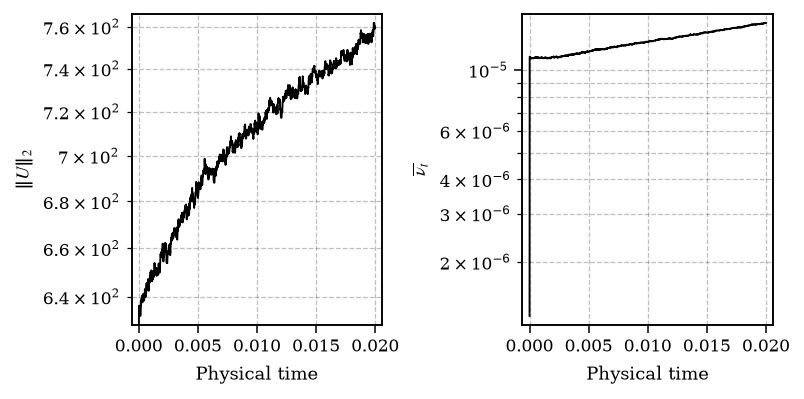

In [73]:
# Plot observations while the solver is running
records = []
figure, axes = plt.subplots(1, 2, figsize=hdg.figsize(column="double"), layout="constrained")
velocity_line, = axes[0].plot([], [], color="black")
nut_line, = axes[1].plot([], [], color="black")

axes[0].set_xlabel("Physical time")
axes[0].set_ylabel(r"$\Vert U \Vert_2$")
axes[1].set_xlabel("Physical time")
axes[1].set_ylabel(r"$\overline{\nu_t}$")

display_handle = display(figure, display_id=True)

for axis in axes:
    axis.set_yscale("log")

for record in run.observe(poll_interval=0.1, progress=True):
    records.append(record)
    physical_time = [item.time for item in records]
    velocity_l2 = [item.summary["U"].l2 for item in records]
    nut_mean = [item.summary["nut"].mean for item in records]

    velocity_line.set_data(physical_time, velocity_l2)
    nut_line.set_data(physical_time, nut_mean)

    for axis in axes:
        axis.relim()

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        for axis in axes:
            axis.autoscale_view()

    for axis in axes:
        axis.grid(True, which="both", alpha=0.25)

    display_handle.update(figure)

plt.close(figure)

In [74]:
# Collect the completed result
result = run.stop(
    force=False,
    timeout=3600.0,
    progress=True,
)

result.summary(
    style="compact",
    display=True,
);

Job ID,Name,Status,Partition,Node,Elapsed
1290237,pitzDailySmag-EquinoxDNN,succeeded,test,rc4184,00:01:05


### Post-processing

In [75]:
# Read the final fields
post = result.postprocess

velocity = post.field(
    name="U",
    time_idx=-1,
    physical_time=None,
)
pressure = post.field(
    name="p",
    time_idx=-1,
    physical_time=None,
)

print("U shape:", velocity.shape)
print("p shape:", pressure.shape)

statistics = post.statistics(
    fields=["U", "p", "nut"],
    time_idx=-1,
    physical_time=None,
    verbose=True,
)

U shape: (12225, 3)
p shape: (12225,)


Field,Min,Max,Mean,Std,RMS
U,6.043590e-03,1.311373e+01,6.348881e+00,2.622216e+00,6.869083e+00
p,-3.246610e+01,1.144830e+02,6.564827e+01,2.152968e+01,6.908851e+01
nut,-3.074590e-06,9.500860e-04,1.486239e-05,4.168337e-05,4.425375e-05
